# Experiment Metrics Exploration

Notebook exploratorio para visualizacao. As metricas oficiais sao calculadas pelo script TypeScript e exportadas em `metrics/`; este notebook apenas consome esses artefatos.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENT_DIR = Path('../results/experiment-runs/poc-ii-pilot-one-question').resolve()
METRICS_DIR = EXPERIMENT_DIR / 'metrics'

per_run = pd.read_csv(METRICS_DIR / 'per-run-metrics.csv')
per_criterion = pd.read_csv(METRICS_DIR / 'per-criterion-metrics.csv')
per_strategy = pd.read_csv(METRICS_DIR / 'per-strategy-summary.csv')
operational = json.loads((METRICS_DIR / 'operational-summary.json').read_text(encoding='utf-8'))
diagnostics = json.loads((METRICS_DIR / 'strategy-diagnostics.json').read_text(encoding='utf-8'))

per_strategy

,strategy,plannedRuns,foundRuns,successRuns,successRate,overallMAE,overallMeanSignedError,criterionMAE,totalCallCount,avgCallCount,totalCostCredits,avgLatencyMs,maxLatencyMs
0,single,3,3,3,1,0.3567,-0.1233,0.7083,3,1,0.015292,9611.6667,9961
1,review,3,3,3,1,0.3900,-0.3233,0.7083,6,2,0.030387,17455.0000,18926
2,multi_aggregate,3,3,3,1,0.3733,-0.1000,0.6958,9,3,0.044560,28042.6667,28838


## MAE por estrategia

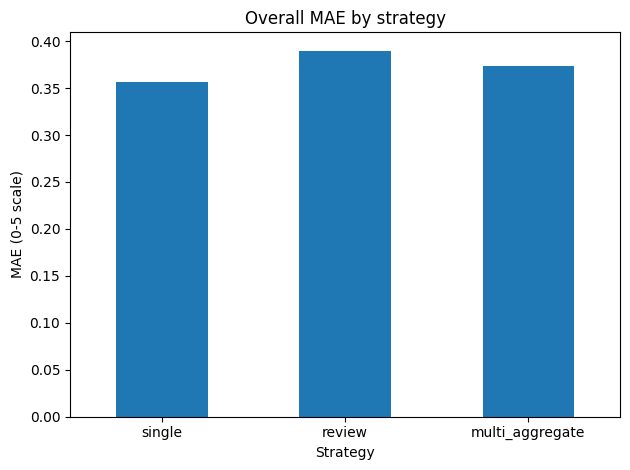

In [2]:
ax = per_strategy.plot.bar(x='strategy', y='overallMAE', legend=False, rot=0)
ax.set_title('Overall MAE by strategy')
ax.set_ylabel('MAE (0-5 scale)')
ax.set_xlabel('Strategy')
plt.tight_layout()

## MAE por profile e estrategia

Esta visao usa a coluna `absoluteError` exportada pelo script oficial e apenas agrega para exploracao visual.

strategy,multi_aggregate,review,single
profile,,,
medium,0.41,0.10,0.35
misleading,0.56,1.00,0.65
strong,0.15,0.07,0.07


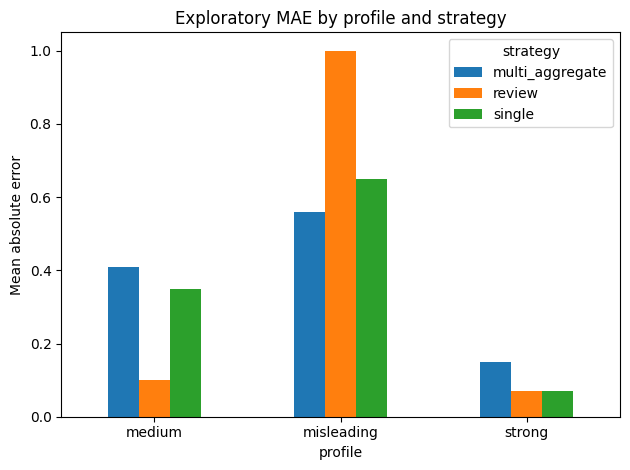

In [3]:
profile_mae = (
    per_run[per_run['status'] == 'success']
    .groupby(['profile', 'strategy'], as_index=False)['absoluteError']
    .mean()
)
pivot = profile_mae.pivot(index='profile', columns='strategy', values='absoluteError')
ax = pivot.plot.bar(rot=0)
ax.set_title('Exploratory MAE by profile and strategy')
ax.set_ylabel('Mean absolute error')
plt.tight_layout()
pivot

## Custo e latencia por estrategia

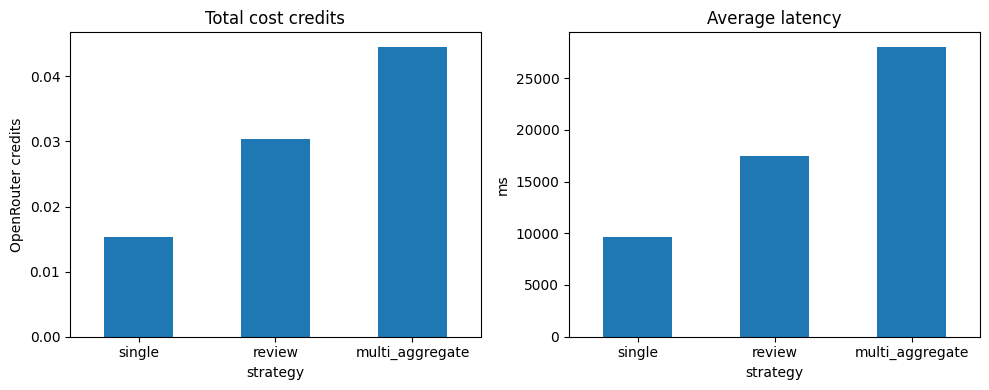

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
per_strategy.plot.bar(x='strategy', y='totalCostCredits', ax=axes[0], legend=False, rot=0)
axes[0].set_title('Total cost credits')
axes[0].set_ylabel('OpenRouter credits')
per_strategy.plot.bar(x='strategy', y='avgLatencyMs', ax=axes[1], legend=False, rot=0)
axes[1].set_title('Average latency')
axes[1].set_ylabel('ms')
plt.tight_layout()

## Erro por criterio

strategy,multi_aggregate,review,single
criterionId,,,
api_contract,0.280000,0.666667,0.500000
backend_flow,0.500000,0.500000,0.500000
http_status_codes,0.613333,0.666667,0.833333
ttl_and_tradeoffs,1.390000,1.000000,1.000000


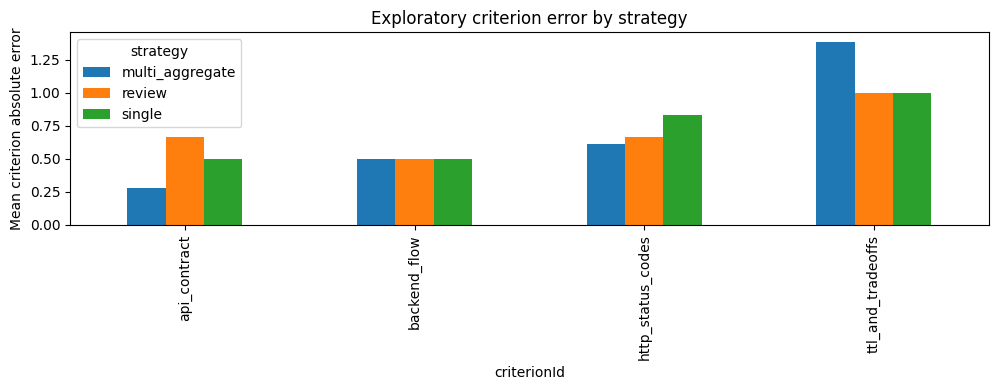

In [5]:
criterion_view = (
    per_criterion
    .groupby(['criterionId', 'strategy'], as_index=False)['criterionAbsoluteError']
    .mean()
)
pivot = criterion_view.pivot(index='criterionId', columns='strategy', values='criterionAbsoluteError')
ax = pivot.plot.bar(figsize=(10, 4))
ax.set_title('Exploratory criterion error by strategy')
ax.set_ylabel('Mean criterion absolute error')
plt.tight_layout()
pivot

## Diagnosticos disponiveis

In [6]:
print(json.dumps(operational, indent=2, ensure_ascii=False))
print(json.dumps(diagnostics, indent=2, ensure_ascii=False))

{
  "experimentId": "poc-ii-pilot-one-question",
  "byStrategy": {
    "single": {
      "foundRuns": 3,
      "totalCallCount": 3,
      "avgCallCount": 1,
      "totalLatencyMs": 28835,
      "avgLatencyMs": 9611.6667,
      "maxLatencyMs": 9961,
      "totalCostCredits": 0.0152918,
      "avgCostCredits": 0.00509727,
      "costAvailableRuns": 3
    },
    "review": {
      "foundRuns": 3,
      "totalCallCount": 6,
      "avgCallCount": 2,
      "totalLatencyMs": 52365,
      "avgLatencyMs": 17455,
      "maxLatencyMs": 18926,
      "totalCostCredits": 0.03038663,
      "avgCostCredits": 0.01012888,
      "costAvailableRuns": 3
    },
    "multi_aggregate": {
      "foundRuns": 3,
      "totalCallCount": 9,
      "avgCallCount": 3,
      "totalLatencyMs": 84128,
      "avgLatencyMs": 28042.6667,
      "maxLatencyMs": 28838,
      "totalCostCredits": 0.04455957,
      "avgCostCredits": 0.01485319,
      "costAvailableRuns": 3
    }
  }
}
{
  "multiAggregate": {
    "availableRuns": 